# 03 · Physics-informed ML — does giving a model physics beat a better architecture?

**Recap of notebook 02 (fair benchmark):**
| Model | Error | Note |
|---|---|---|
| M0 physics formula | 4.7 % | no learning |
| M2 boosted trees | 3.4 % | |
| M3 Gaussian process | 2.1 % | best so far |
| M1 paper's network | 1.8–2.2 % on 4 seeds, **40 % on 1 seed** | unstable: 1 in 5 trainings collapses |
| M5 small MLP | 3.2 % | untuned, stopped training too early |

Every model still fails on **fat hulls** (15–19 %).

**This notebook asks:** is it the *architecture* that matters, or *what we tell the model about physics*? We test:
1. **Tuning** — give every neural model the same fair tuning budget (cross-validation).
2. **Ablation** — the same MLP with raw vs **physics inputs**, and predicting drag vs **the correction to physics**.
3. **M4** — the full hybrid, plus a **physics penalty** (drag may never drop when the hull gets longer or wider).
4. **M6** — a **deep ensemble** (5 networks averaged) that also says how uncertain it is.
5. **Learning curves** — how much data each approach needs.
6. **Out-of-distribution test** — train without fat hulls, test on fat hulls.

> ⏱ Full run: roughly **45–90 minutes** in total on a laptop CPU (tuning and learning curves are the slow parts).
> Set `QUICK = True` in the next cell for a 5-minute rehearsal with tiny settings.

In [2]:
import sys
sys.path.insert(0, '..')
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from models import harness
from models import physics_ml as pm

QUICK = False                                   # True = tiny settings, to check everything runs
X_train, y_train, X_test, y_test = harness.load_data()
print('train', X_train.shape, 'test', X_test.shape, '| QUICK mode' if QUICK else '| full mode')

train (2400, 6) test (621, 6) | full mode


---
## 1 · What does "giving a model physics" mean?

### 1.1 Physics inputs (dimensionless groups)
Raw inputs are lengths in millimetres. But physics doesn't care about millimetres — it cares about **proportions**.
A hull twice as big in every direction, moving in the same water, behaves according to the same ratios. Engineers
call these **dimensionless groups** (the *Buckingham Π* idea). We replace the 6 raw numbers with 8 ratios:

| Feature | Meaning |
|---|---|
| d/L | thickness relative to length (1 / fineness) — *the* number for separation |
| a/L, c/L | how much of the hull is nose / tail |
| n | nose bluntness (already dimensionless) |
| tan θ | tail steepness |
| d/(2c) | how quickly the tail has to close the hull |
| Cp | "fullness": volume ÷ (frontal area × length) |
| log₁₀ Re | Reynolds number: speed × length ÷ viscosity — the flow regime |

### 1.2 A physics target (predict the correction, not the drag)
Instead of predicting drag directly, the network predicts **how wrong the physics formula is**:

$$\text{drag} = \underbrace{\text{M0 physics drag}}_{\text{known}} \times \underbrace{\text{correction}}_{\text{learned}}$$

For slender hulls the correction is ≈ 1 (physics is right); for fat hulls it is > 1 (pressure drag). The network only
has to learn the *difference* — a much easier job. (Technically we learn log(correction), so errors are relative.)

            d/L        a/L        c/L          n tan(theta)     d/(2c)         Cp  log10(Re)
   0      0.097      0.229      0.264      3.050      1.161      0.184      0.979      6.106
   1      0.095      0.164      0.261      3.559      0.712      0.182      0.899      6.233
   2      0.144      0.262      0.331      3.871      0.252      0.218      0.762      6.127
   3      0.071      0.076      0.119      4.841      0.169      0.296      0.916      6.286
   4      0.085      0.090      0.193      3.546      0.255      0.220      0.874      6.180


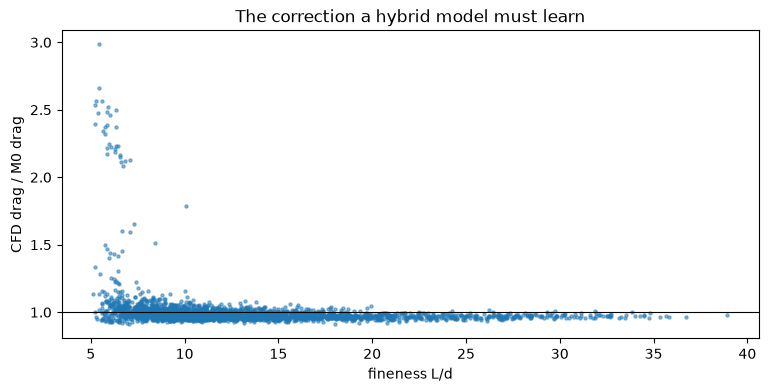

In [3]:
F = pm.physics_features(X_train[:5])
print(f'{"":4s}' + ''.join(f'{n:>11s}' for n in pm.FEATURE_NAMES))
for i, row in enumerate(F):
    print(f'{i:4d}' + ''.join(f'{v:11.3f}' for v in row))

corr = y_train / pm.m0_drag(X_train)          # the correction factor each training hull needs
ld = harness.fineness(X_train)
plt.figure(figsize=(9, 4))
plt.scatter(ld, corr, s=5, alpha=0.5); plt.axhline(1, c='k', lw=0.8)
plt.xlabel('fineness L/d'); plt.ylabel('CFD drag / M0 drag'); plt.title('The correction a hybrid model must learn')
plt.show()

### 1.3 The hybrid model (M4) as a picture

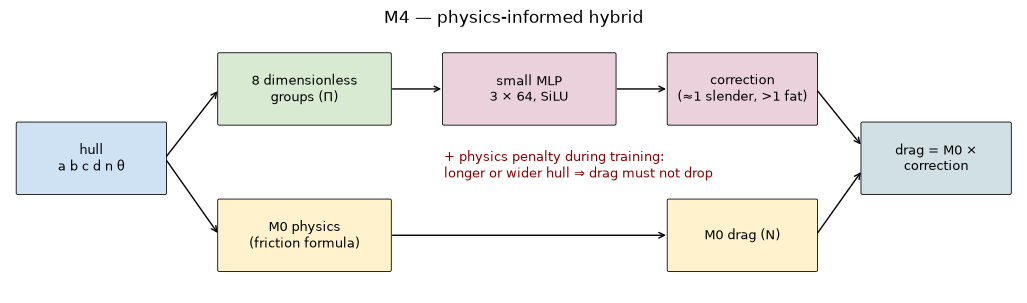

In [4]:
def box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02', fc=color, ec='k', lw=0.6))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=9)
def arrow(ax, x1, y1, x2, y2):
    ax.annotate('', (x2, y2), (x1, y1), arrowprops=dict(arrowstyle='->', lw=1))

fig, ax = plt.subplots(figsize=(13, 3.4)); ax.axis('off'); ax.set_xlim(0, 13); ax.set_ylim(0, 3.4)
box(ax, 0.1, 1.3, 1.9, 0.9, 'hull\na b c d n θ', '#cfe2f3')
box(ax, 2.7, 2.2, 2.2, 0.9, '8 dimensionless\ngroups (Π)', '#d9ead3')
box(ax, 2.7, 0.3, 2.2, 0.9, 'M0 physics\n(friction formula)', '#fff2cc')
box(ax, 5.6, 2.2, 2.2, 0.9, 'small MLP\n3 × 64, SiLU', '#ead1dc')
box(ax, 8.5, 2.2, 1.9, 0.9, 'correction\n(≈1 slender, >1 fat)', '#ead1dc')
box(ax, 8.5, 0.3, 1.9, 0.9, 'M0 drag (N)', '#fff2cc')
box(ax, 11.0, 1.3, 1.9, 0.9, 'drag = M0 ×\ncorrection', '#d0e0e3')
for (x1, y1, x2, y2) in [(2.0, 1.75, 2.7, 2.65), (2.0, 1.75, 2.7, 0.75), (4.9, 2.65, 5.6, 2.65), (7.8, 2.65, 8.5, 2.65),
                         (4.9, 0.75, 8.5, 0.75), (10.4, 2.65, 11.0, 1.9), (10.4, 0.75, 11.0, 1.6)]:
    arrow(ax, x1, y1, x2, y2)
ax.text(5.6, 1.5, '+ physics penalty during training:\nlonger or wider hull ⇒ drag must not drop', fontsize=9, color='darkred')
ax.set_title('M4 — physics-informed hybrid'); plt.show()

---
## 2 · Fair tuning with cross-validation

Every MLP variant gets **the same tuning budget**: the same random list of settings, each scored by **3-fold
cross-validation** on the training hulls only (train on 2/3, validate on 1/3, rotate, average).
The **test set is not touched**. We then keep each variant's best setting.

Settings searched: width (32 / 64 / 128), depth (2 / 3 / 4), learning rate (3e-4 / 1e-3 / 3e-3), weight decay (0 / 1e-4 / 1e-3).

In [5]:
rng = np.random.default_rng(42)
GRID = [dict(width=int(w), depth=int(d), lr=float(l), weight_decay=float(wd))
        for w, d, l, wd in zip(rng.choice([32, 64, 128], 8), rng.choice([2, 3, 4], 8),
                               rng.choice([3e-4, 1e-3, 3e-3], 8), rng.choice([0.0, 1e-4, 1e-3], 8))]
EPOCHS = dict(epochs=40, patience=40) if QUICK else dict(epochs=1000, patience=100)
GRID = GRID[:2] if QUICK else GRID
FOLDS = 2 if QUICK else 3

def cv_score(variant, cfg, penalty=None):
    """Average validation MAPE over k folds of the training set (test set untouched)."""
    idx = np.random.default_rng(0).permutation(len(X_train))
    errs = []
    for k, va in enumerate(np.array_split(idx, FOLDS)):
        tr = np.setdiff1d(idx, va)
        f = pm.fit_variant(variant, X_train[tr], y_train[tr], X_train[va], y_train[va], {**cfg, **EPOCHS}, seed=k, penalty=penalty)
        errs.append(np.mean(np.abs(f(X_train[va]) - y_train[va]) / y_train[va]) * 100)
    return np.mean(errs)

VARIANTS = {'raw inputs → drag': pm.Variant('raw', 'drag'),
            'raw inputs → correction': pm.Variant('raw', 'correction'),
            'physics inputs → drag': pm.Variant('physics', 'drag'),
            'physics inputs → correction': pm.Variant('physics', 'correction')}
best_cfg = {}
for name, v in VARIANTS.items():
    t0 = time.time()
    scores = [cv_score(v, cfg) for cfg in GRID]
    best_cfg[name] = GRID[int(np.argmin(scores))]
    print(f'{name:30s} best CV error {min(scores):5.2f} %  with {best_cfg[name]}   ({time.time() - t0:.0f} s)')

raw inputs → drag              best CV error  2.77 %  with {'width': 128, 'depth': 2, 'lr': 0.0003, 'weight_decay': 0.0001}   (118 s)
raw inputs → correction        best CV error  1.96 %  with {'width': 64, 'depth': 3, 'lr': 0.003, 'weight_decay': 0.0001}   (97 s)
physics inputs → drag          best CV error  2.45 %  with {'width': 64, 'depth': 4, 'lr': 0.001, 'weight_decay': 0.001}   (110 s)
physics inputs → correction    best CV error  1.99 %  with {'width': 64, 'depth': 3, 'lr': 0.003, 'weight_decay': 0.0001}   (106 s)


---
## 3 · The ablation (2 × 2)
Each variant is retrained with its best setting, 5 seeds, and scored on the test set through the same harness as
notebook 02 (so the numbers are directly comparable and saved to `results/benchmark.csv`).

In [6]:
SEEDS = (0, 1) if QUICK else (0, 1, 2, 3, 4)
for name, v in VARIANTS.items():
    cfg = {**best_cfg[name], **EPOCHS}
    harness.run(f'MLP {name}', lambda Xtr, ytr, Xv, yv, Xte, s, v=v, cfg=cfg: pm.fit_variant(v, Xtr, ytr, Xv, yv, cfg, s)(Xte), seeds=SEEDS)

MLP raw inputs → drag        seed 0:  3.27 %   fat hulls  18.5 %   (16.4 s)
MLP raw inputs → drag        seed 1:  3.06 %   fat hulls  17.5 %   (3.7 s)
MLP raw inputs → drag        seed 2:  3.02 %   fat hulls  18.5 %   (12.2 s)
MLP raw inputs → drag        seed 3:  3.22 %   fat hulls  18.1 %   (3.1 s)
MLP raw inputs → drag        seed 4:  3.45 %   fat hulls  18.3 %   (3.4 s)
MLP raw inputs → correction  seed 0:  1.63 %   fat hulls  12.1 %   (5.0 s)
MLP raw inputs → correction  seed 1:  1.80 %   fat hulls  13.4 %   (4.5 s)
MLP raw inputs → correction  seed 2:  2.00 %   fat hulls  15.9 %   (3.0 s)
MLP raw inputs → correction  seed 3:  1.79 %   fat hulls  12.1 %   (5.0 s)
MLP raw inputs → correction  seed 4:  1.85 %   fat hulls  13.5 %   (2.8 s)
MLP physics inputs → drag    seed 0:  2.46 %   fat hulls  19.9 %   (8.4 s)
MLP physics inputs → drag    seed 1:  3.03 %   fat hulls  17.6 %   (2.9 s)
MLP physics inputs → drag    seed 2:  1.75 %   fat hulls  13.3 %   (15.8 s)
MLP physics inputs → d

---
## 4 · M4 — the hybrid with a physics penalty
Same as "physics inputs → correction", plus the **penalty**: on 256 random *unlabelled* hulls (no CFD needed), the
training loss grows whenever the model predicts **less** drag for a longer body or a larger diameter. These are
**collocation points** — the same trick physics-informed neural networks (PINNs) use to enforce equations.

In [7]:
PENALTY = pm.MonotonicPenalty(n_points=64 if QUICK else 256, weight=1.0)
cfg4 = {**best_cfg['physics inputs → correction'], **EPOCHS}
harness.run('M4 hybrid + physics penalty',
            lambda Xtr, ytr, Xv, yv, Xte, s: pm.fit_variant(VARIANTS['physics inputs → correction'], Xtr, ytr, Xv, yv, cfg4, s, penalty=PENALTY)(Xte),
            seeds=SEEDS)

M4 hybrid + physics penalty  seed 0:  1.58 %   fat hulls  11.3 %   (21.3 s)
M4 hybrid + physics penalty  seed 1:  1.76 %   fat hulls  12.1 %   (22.4 s)
M4 hybrid + physics penalty  seed 2:  2.11 %   fat hulls  17.9 %   (24.7 s)
M4 hybrid + physics penalty  seed 3:  1.60 %   fat hulls  12.9 %   (27.5 s)
M4 hybrid + physics penalty  seed 4:  1.41 %   fat hulls  10.6 %   (15.7 s)


[{'model': 'M4 hybrid + physics penalty',
  'seed': 0,
  'train_seconds': 21.325347661972046,
  'mape': np.float64(1.5839512112343626),
  'max_err': np.float64(61.044185141535635),
  'mape_fat': np.float64(11.316914083548),
  'mape_typical': np.float64(1.1415406585913237),
  'mape_slender': np.float64(0.48538800506568164),
  'mape_very_slender': np.float64(0.6140964020486497)},
 {'model': 'M4 hybrid + physics penalty',
  'seed': 1,
  'train_seconds': 22.412838220596313,
  'mape': np.float64(1.7580164705703663),
  'max_err': np.float64(63.991222853376385),
  'mape_fat': np.float64(12.088135146856137),
  'mape_typical': np.float64(1.3024040979688347),
  'mape_slender': np.float64(0.6857515518380495),
  'mape_very_slender': np.float64(0.5986651317141811)},
 {'model': 'M4 hybrid + physics penalty',
  'seed': 2,
  'train_seconds': 24.701058864593506,
  'mape': np.float64(2.106604913368919),
  'max_err': np.float64(124.28976845445048),
  'mape_fat': np.float64(17.88723062775718),
  'mape_typ

### 4.1 Physical-consistency audit
Accuracy is not everything. A model used for **design** must respond sensibly when the design changes. We check every
model on 1,000 random hulls: how often does predicted drag **drop** when the body gets 5 % longer, or the diameter 5 %
larger? (Physically it should never drop.)

In [8]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

tr, va = harness.train_val_split(len(X_train), 0)
Xa, ya, Xv, yv = X_train[tr], y_train[tr], X_train[va], y_train[va]
models = {'M0 physics': pm.m0_drag}
m2 = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=0).fit(Xa, ya)
models['M2 boosted trees'] = m2.predict
n_gp = 300 if QUICK else len(Xa)
sgp = StandardScaler().fit(Xa[:n_gp])
gp = GaussianProcessRegressor(ConstantKernel() * Matern(np.ones(6), nu=2.5) + WhiteKernel(), normalize_y=True,
                              random_state=0).fit(sgp.transform(Xa[:n_gp]), np.log(ya[:n_gp]))
models['M3 Gaussian process'] = lambda X: np.exp(gp.predict(sgp.transform(X)))
models['MLP raw → drag'] = pm.fit_variant(VARIANTS['raw inputs → drag'], Xa, ya, Xv, yv, {**best_cfg['raw inputs → drag'], **EPOCHS}, 0)
models['M4 hybrid + penalty'] = pm.fit_variant(VARIANTS['physics inputs → correction'], Xa, ya, Xv, yv, cfg4, 0, penalty=PENALTY)

probe = pm.random_hulls(200 if QUICK else 1000, seed=7)
print(f'{"model":24s} {"longer body ⇒ less drag":>26s} {"wider ⇒ less drag":>20s}')
for name, f in models.items():
    v = pm.monotonicity_violations(f, probe)
    print(f'{name:24s} {v["longer_body"]:25.1f}% {v["larger_diameter"]:19.1f}%')

model                       longer body ⇒ less drag    wider ⇒ less drag
M0 physics                                     0.0%                 0.0%
M2 boosted trees                              11.1%                 3.1%
M3 Gaussian process                           16.5%                 2.9%
MLP raw → drag                                 9.4%                 0.0%
M4 hybrid + penalty                            4.1%                 2.9%


---
## 5 · M6 — deep ensemble: how sure is the model?
Train **5 networks** (different seeds and validation splits) and average them. Where they **disagree**, the model is
unsure. We use their spread (standard deviation) as an error bar and check: do ~95 % of true drags fall within
± 2 standard deviations? (For comparison, the Gaussian process reached 96 % in notebook 02.)

M6 ensemble of 5: error 1.59 %, fat hulls 11.8 %, 78 % of test hulls inside ±2σ (ideal ≈ 95 %)


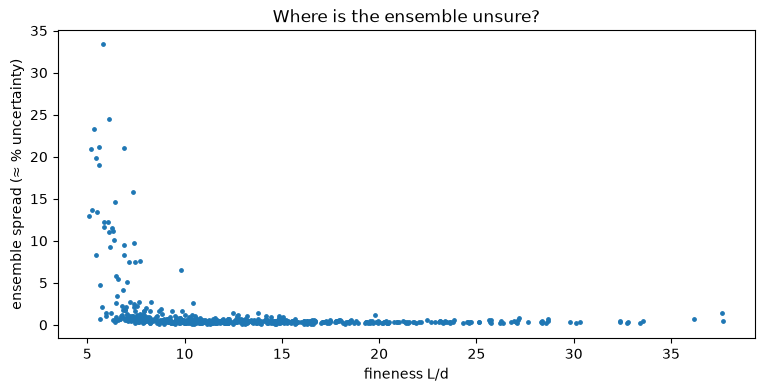

In [9]:
v = VARIANTS['physics inputs → correction']
members = []
for s in SEEDS:
    tr_s, va_s = harness.train_val_split(len(X_train), 100 + s)
    members.append(pm.fit_variant(v, X_train[tr_s], y_train[tr_s], X_train[va_s], y_train[va_s], cfg4, s, penalty=PENALTY))
logp = np.array([np.log(f(X_test)) for f in members])           # members × hulls, in log space
mean, std = logp.mean(0), logp.std(0)
pred6 = np.exp(mean)
inside = np.mean(np.abs(np.log(y_test) - mean) < 2 * std) * 100
m = harness.metrics(pred6, y_test, X_test)
print(f'M6 ensemble of {len(members)}: error {m["mape"]:.2f} %, fat hulls {m["mape_fat"]:.1f} %, '
      f'{inside:.0f} % of test hulls inside ±2σ (ideal ≈ 95 %)')
harness._append([{'model': 'M6 deep ensemble (hybrid)', 'seed': 0, 'train_seconds': float('nan'), **m}])

ld_t = harness.fineness(X_test)
plt.figure(figsize=(9, 4))
plt.scatter(ld_t, 100 * std, s=6); plt.xlabel('fineness L/d'); plt.ylabel('ensemble spread (≈ % uncertainty)')
plt.title('Where is the ensemble unsure?'); plt.show()

---
## 6 · Learning curves — how much data does each approach need?
We train on only **N** hulls (N = 50 … all) and score on the full test set. If physics helps, the hybrid should reach a
given accuracy with **far fewer** CFD simulations — which matters because each simulation costs ~20 CPU-minutes.

N =    50: M3 Gaussian process 5.90%   MLP raw → drag 4.40%   M4 hybrid + penalty 2.96%
N =   100: M3 Gaussian process 2.62%   MLP raw → drag 4.51%   M4 hybrid + penalty 2.10%


/Users/nallasaikirankumar/Projects/rbc-shear-surrogate/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


N =   250: M3 Gaussian process 3.94%   MLP raw → drag 4.48%   M4 hybrid + penalty 4.46%
N =   500: M3 Gaussian process 2.23%   MLP raw → drag 4.64%   M4 hybrid + penalty 2.54%
N =  1000: M3 Gaussian process 2.17%   MLP raw → drag 3.91%   M4 hybrid + penalty 2.45%


/Users/nallasaikirankumar/Projects/rbc-shear-surrogate/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 46 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


N =  2160: M3 Gaussian process 1.96%   MLP raw → drag 3.16%   M4 hybrid + penalty 1.96%


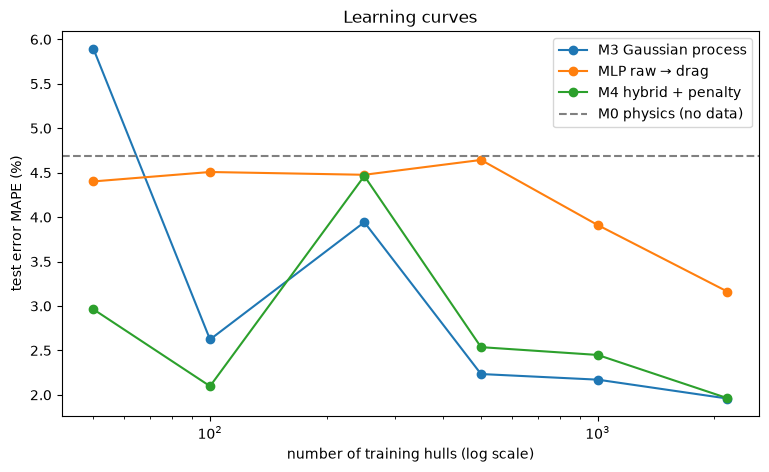

In [10]:
Ns = [50, 200] if QUICK else [50, 100, 250, 500, 1000, 2160]
curve = {k: [] for k in ['M3 Gaussian process', 'MLP raw → drag', 'M4 hybrid + penalty']}
for N in Ns:
    sub = np.random.default_rng(N).choice(len(Xa), N, replace=False)
    nv = max(10, N // 10)
    Xs, ys, Xsv, ysv = Xa[sub[nv:]], ya[sub[nv:]], Xa[sub[:nv]], ya[sub[:nv]]
    s_ = StandardScaler().fit(Xs)
    g = GaussianProcessRegressor(ConstantKernel() * Matern(np.ones(6), nu=2.5) + WhiteKernel(), normalize_y=True,
                                 random_state=0).fit(s_.transform(Xs), np.log(ys))
    curve['M3 Gaussian process'].append(harness.metrics(np.exp(g.predict(s_.transform(X_test))), y_test, X_test)['mape'])
    f = pm.fit_variant(VARIANTS['raw inputs → drag'], Xs, ys, Xsv, ysv, {**best_cfg['raw inputs → drag'], **EPOCHS}, 0)
    curve['MLP raw → drag'].append(harness.metrics(f(X_test), y_test, X_test)['mape'])
    f = pm.fit_variant(VARIANTS['physics inputs → correction'], Xs, ys, Xsv, ysv, cfg4, 0, penalty=PENALTY)
    curve['M4 hybrid + penalty'].append(harness.metrics(f(X_test), y_test, X_test)['mape'])
    print(f'N = {N:5d}: ' + '   '.join(f'{k} {v[-1]:.2f}%' for k, v in curve.items()))

plt.figure(figsize=(9, 5))
for k, v in curve.items():
    plt.plot(Ns, v, 'o-', label=k)
plt.axhline(harness.metrics(pm.m0_drag(X_test), y_test, X_test)['mape'], ls='--', c='gray', label='M0 physics (no data)')
plt.xscale('log'); plt.xlabel('number of training hulls (log scale)'); plt.ylabel('test error MAPE (%)')
plt.title('Learning curves'); plt.legend(); plt.show()

---
## 7 · Out-of-distribution test — can a model handle hulls unlike its training data?
We **remove all fat hulls (L/d < 7) from training**, then test only on the fat test hulls. This mimics a designer
asking about a shape outside the data. Physics-based models should degrade more gracefully.

In [11]:
keep = harness.fineness(Xa) >= 7
fat_test = harness.fineness(X_test) < 7
ood = {}
ood['M0 physics'] = pm.m0_drag(X_test[fat_test])
s_ = StandardScaler().fit(Xa[keep][:n_gp])
g = GaussianProcessRegressor(ConstantKernel() * Matern(np.ones(6), nu=2.5) + WhiteKernel(), normalize_y=True,
                             random_state=0).fit(s_.transform(Xa[keep][:n_gp]), np.log(ya[keep][:n_gp]))
ood['M3 Gaussian process'] = np.exp(g.predict(s_.transform(X_test[fat_test])))
ood['MLP raw → drag'] = pm.fit_variant(VARIANTS['raw inputs → drag'], Xa[keep], ya[keep], Xv, yv,
                                       {**best_cfg['raw inputs → drag'], **EPOCHS}, 0)(X_test[fat_test])
ood['M4 hybrid + penalty'] = pm.fit_variant(VARIANTS['physics inputs → correction'], Xa[keep], ya[keep], Xv, yv,
                                            cfg4, 0, penalty=PENALTY)(X_test[fat_test])
print('Error on the 50 fat test hulls, when NO fat hulls were seen in training:')
for k, p in ood.items():
    print(f'   {k:24s} {np.mean(np.abs(p - y_test[fat_test]) / y_test[fat_test]) * 100:6.1f} %')

/Users/nallasaikirankumar/Projects/rbc-shear-surrogate/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 34 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/nallasaikirankumar/Projects/rbc-shear-surrogate/.venv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Error on the 50 fat test hulls, when NO fat hulls were seen in training:
   M0 physics                 18.5 %
   M3 Gaussian process        47.7 %
   MLP raw → drag             16.6 %
   M4 hybrid + penalty        15.1 %


---
## 8 · All results together

In [12]:
table = harness.summary()
print(f'{"model":38s}{"overall":>16s}{"fat":>16s}{"slender":>16s}')
for name, v in sorted(table.items(), key=lambda kv: kv[1]['mape'][0]):
    print(f'{name:38s}{v["mape"][0]:9.2f} ±{v["mape"][1]:5.2f}{v["mape_fat"][0]:9.2f} ±{v["mape_fat"][1]:5.2f}'
          f'{v["mape_slender"][0]:9.2f} ±{v["mape_slender"][1]:5.2f}')

model                                          overall             fat         slender
M6 deep ensemble (hybrid)                  1.59 ± 0.00    11.84 ± 0.00     0.47 ± 0.00
M4 hybrid + physics penalty                1.69 ± 0.23    12.96 ± 2.58     0.51 ± 0.09
MLP physics inputs → correction            1.71 ± 0.22    12.44 ± 1.69     0.55 ± 0.13
MLP raw inputs → correction                1.81 ± 0.12    13.38 ± 1.39     0.55 ± 0.04
M3 Gaussian process                        2.06 ± 0.00    16.62 ± 0.00     0.56 ± 0.00
MLP physics inputs → drag                  2.49 ± 0.60    16.18 ± 2.81     0.86 ± 0.29
M1a paper code as run                      2.68 ± 0.49    15.76 ± 2.80     1.19 ± 0.42
M5 small modern MLP                        3.16 ± 0.32    17.51 ± 1.13     1.33 ± 0.18
MLP raw inputs → drag                      3.20 ± 0.16    18.16 ± 0.39     1.26 ± 0.10
M2 boosted trees                           3.37 ± 0.10    15.11 ± 0.52     1.79 ± 0.09
M0 physics                                 

### ✍️ Questions
1. **Ablation:** which change helped more — physics *inputs* or the physics *target*? Do they add up?
2. Does the hybrid (M4) beat the Gaussian process overall? On fat hulls?
3. **Consistency:** which models break the "longer ⇒ more drag" rule, and how often? Why does that matter for design?
4. **Learning curves:** at N = 100, how big is the gap between the hybrid and the raw MLP? What does that mean in
   CFD hours saved?
5. **Out of distribution:** which model is least wrong on fat hulls it never saw? Why?
6. Write **three sentences** you could say in an interview about what this notebook shows.